In [1]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
!pip install torch==2.1.2 torchvision==0.16.2 torchaudio==2.1.2 --index-url https://download.pytorch.org/whl/cpu
!pip install mamkit --upgrade

Looking in indexes: https://download.pytorch.org/whl/cpu
  Using cached https://download.pytorch.org/whl/cpu/torch-2.1.2%2Bcpu-cp311-cp311-linux_x86_64.whl (184.9 MB)
  Using cached https://download.pytorch.org/whl/cpu/torchaudio-2.1.2%2Bcpu-cp311-cp311-linux_x86_64.whl (1.6 MB)
  Attempting uninstall: torch
    Found existing installation: torch 2.3.0
    Uninstalling torch-2.3.0:
      Successfully uninstalled torch-2.3.0
  Attempting uninstall: torchaudio
    Found existing installation: torchaudio 2.3.0
    Uninstalling torchaudio-2.3.0:
      Successfully uninstalled torchaudio-2.3.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torchtext 0.18.0 requires torch>=2.3.0, but you have torch 2.1.2+cpu which is incompatible.
mamkit 0.1.1 requires torch==2.3.0, but you have torch 2.1.2+cpu which is incompatible.
mamkit 0.1.1 requires torchaudio==2.3.0, but you 

In [3]:

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split, Dataset, Subset
from transformers import RobertaTokenizer, RobertaModel, AdamW
from sklearn.metrics import f1_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
import os

from mamkit.data.datasets import MMUSEDFallacy, InputMode

/usr/local/lib/python3.11/dist-packages/torchvision/io/image.py:13: UserWarning: Failed to load image Python extension: '/usr/local/lib/python3.11/dist-packages/torchvision/image.so: undefined symbol: _ZN3c1017RegisterOperatorsD1Ev'If you don't plan on using image functionality from `torchvision.io`, you can ignore this warning. Otherwise, there might be something wrong with your environment. Did you have `libjpeg` or `libpng` installed before building `torchvision` from source?
  warn(


In [4]:
# --- Load AFC Dataset (6-class classification) ---
base_data_path = Path("/content/data")
full_dataset = MMUSEDFallacy(task_name='afc', input_mode=InputMode.TEXT_ONLY, base_data_path=base_data_path)

Downloading: https://zenodo.org/api/records/14938117/files-archive: 5.71MB [00:08, 677kB/s]
  0%|          | 0/35 [00:00<?, ?it/s]

[youtube] Extracting URL: https://www.youtube.com/watch?v=_hEeMvhcNlE&t=4579s
[youtube] _hEeMvhcNlE: Downloading webpage
[youtube] _hEeMvhcNlE: Downloading tv client config
[youtube] _hEeMvhcNlE: Downloading player aa3fc80b
[youtube] _hEeMvhcNlE: Downloading tv player API JSON
[youtube] _hEeMvhcNlE: Downloading ios player API JSON


         player = https://www.youtube.com/s/player/aa3fc80b/player_ias.vflset/en_US/base.js
         n = Drm_c1vOmHB43ppjHH5-oG ; player = https://www.youtube.com/s/player/aa3fc80b/player_ias.vflset/en_US/base.js
         player = https://www.youtube.com/s/player/aa3fc80b/player_ias.vflset/en_US/base.js
         n = QncjJyjgZp2nFoYsVAdmie ; player = https://www.youtube.com/s/player/aa3fc80b/player_ias.vflset/en_US/base.js
         player = https://www.youtube.com/s/player/aa3fc80b/player_ias.vflset/en_US/base.js
         n = u_EBvLyG4iv0Fb1kORUEPU ; player = https://www.youtube.com/s/player/aa3fc80b/player_ias.vflset/en_US/base.js


[youtube] _hEeMvhcNlE: Downloading m3u8 information
[info] _hEeMvhcNlE: Downloading 1 format(s): 234
[hlsnative] Downloading m3u8 manifest
[hlsnative] Total fragments: 1094
[download] Destination: /content/data/MMUSED-fallacy/audio_recordings/30_2004/full_audio
[download] 100% of   90.82MiB in 00:01:25 at 1.06MiB/s                     
[ExtractAudio] Destination: /content/data/MMUSED-fallacy/audio_recordings/30_2004/full_audio.wav
Deleting original file /content/data/MMUSED-fallacy/audio_recordings/30_2004/full_audio (pass -k to keep)


  3%|▎         | 1/35 [01:40<56:56, 100.50s/it]

[youtube] Extracting URL: https://www.youtube.com/watch?v=xdQK78l3Xhc&t=119s
[youtube] xdQK78l3Xhc: Downloading webpage
[youtube] xdQK78l3Xhc: Downloading tv client config
[youtube] xdQK78l3Xhc: Downloading player aa3fc80b
[youtube] xdQK78l3Xhc: Downloading tv player API JSON
[youtube] xdQK78l3Xhc: Downloading ios player API JSON


... (131 outputs left out)

[youtube] Extracting URL: https://www.youtube.com/watch?v=UCA1A5GqCdQ&ab_channel=NBCNews
[youtube] UCA1A5GqCdQ: Downloading webpage
[youtube] UCA1A5GqCdQ: Downloading tv client config
[youtube] UCA1A5GqCdQ: Downloading player aa3fc80b
[youtube] UCA1A5GqCdQ: Downloading tv player API JSON
[youtube] UCA1A5GqCdQ: Downloading ios player API JSON


         player = https://www.youtube.com/s/player/aa3fc80b/player_ias.vflset/en_US/base.js
         n = 0-HKaFn-OQIeZq-Rto2-9o ; player = https://www.youtube.com/s/player/aa3fc80b/player_ias.vflset/en_US/base.js
         player = https://www.youtube.com/s/player/aa3fc80b/player_ias.vflset/en_US/base.js
         n = Jji-FiliyJPnwiBqvgC6sm ; player = https://www.youtube.com/s/player/aa3fc80b/player_ias.vflset/en_US/base.js
         player = https://www.youtube.com/s/player/aa3fc80b/player_ias.vflset/en_US/base.js
         n = kN5z1qbn3xCHwWjtGOwOiP ; player = https://www.youtube.com/s/player/aa3fc80b/player_ias.vflset/en_US/base.js


[youtube] UCA1A5GqCdQ: Downloading m3u8 information
[info] UCA1A5GqCdQ: Downloading 1 format(s): 234
[hlsnative] Downloading m3u8 manifest
[hlsnative] Total fragments: 1345
[download] Destination: /content/data/MMUSED-fallacy/audio_recordings/46_2020/full_audio
[download] 100% of  111.60MiB in 00:01:46 at 1.05MiB/s                     
[ExtractAudio] Destination: /content/data/MMUSED-fallacy/audio_recordings/46_2020/full_audio.wav
Deleting original file /content/data/MMUSED-fallacy/audio_recordings/46_2020/full_audio (pass -k to keep)


Building clips...: 100%|██████████| 35/35 [05:23<00:00,  9.25s/it]


In [37]:
# --- Wrap AFC Dataset ---
class WrappedAFC(Dataset):
    def __init__(self, mmused_dataset, tokenizer, max_length):
        self.df = mmused_dataset.data  # correct: access the .data DataFrame
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        text = row['snippet']
        label = row['fallacy']
        inputs = self.tokenizer(text, padding='max_length', truncation=True,
                                max_length=self.max_length, return_tensors="pt")
        # Remove batch dimension
        item = {key: val.squeeze(0) for key, val in inputs.items()}
        item['label'] = torch.tensor(label)
        return item

    def __len__(self):
        return len(self.df)

wrapped_dataset = WrappedAFC(full_dataset, tokenizer, max_length=128)
# Create a valid subset of the dataset using the actual number of samples
subset_indices = list(range(len(wrapped_dataset)))  # Use all available indices (1278 samples)
subset_dataset = Subset(wrapped_dataset, subset_indices)

In [57]:
# --- Split Data ---
train_size = int(0.8 * len(subset_dataset))
val_size = len(subset_dataset) - train_size
train_dataset, val_dataset = random_split(subset_dataset, [train_size, val_size])

tokenizer = RobertaTokenizer.from_pretrained('roberta-base')

def collate_fn(batch):
    input_keys = batch[0].keys()
    input_tensors = {k: torch.stack([d[k] for d in batch]) for k in input_keys if k != 'label'}
    labels = torch.tensor([d['label'] for d in batch])
    return input_tensors, labels




train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False, collate_fn=collate_fn)


In [48]:
# --- Define 6-Class Classifier ---
class RobertaFallacyClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.roberta = RobertaModel.from_pretrained('roberta-base')
        self.classifier = nn.Linear(self.roberta.config.hidden_size, 6)  # AFC = 6 fallacy types

    def forward(self, input_ids, attention_mask):
        outputs = self.roberta(input_ids=input_ids, attention_mask=attention_mask)
        pooled_output = outputs.last_hidden_state[:, 0]
        return self.classifier(pooled_output)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = RobertaFallacyClassifier().to(device)


Some weights of RobertaModel were not initialized from the model checkpoint at roberta-base and are newly initialized: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [10]:
print(dataset.data.shape)       # Rows (samples), Columns (fields)
print(dataset.data.head())     # First few samples


Building AFD data...: 100%|██████████| 35/35 [00:03<00:00, 10.76it/s]


(17118, 7)
                                       context_paths  \
0                                                 []   
1  [/content/data/MMUSED-fallacy/audio_clips/10_1...   
2  [/content/data/MMUSED-fallacy/audio_clips/10_1...   
3  [/content/data/MMUSED-fallacy/audio_clips/10_1...   
4  [/content/data/MMUSED-fallacy/audio_clips/10_1...   

                                             context  \
0                                                      
1                I have a plan -- not a secret plan.   
2  I have a plan -- not a secret plan. As a matte...   
3  I have a plan -- not a secret plan. As a matte...   
4  As a matter of fact, it is the economic recove...   

                                            sentence  \
0                I have a plan -- not a secret plan.   
1  As a matter of fact, it is the economic recove...   
2  It is true that earlier, working with some ver...   
3  Before even the election day, something that n...   
4  Under that, this year, we have s

In [12]:
print(len(train_loader), len(val_loader))


100 25


In [58]:
# --- Optimizer and Loss ---
optimizer = AdamW(model.parameters(), lr=2e-5)
loss_fn = nn.CrossEntropyLoss()

# --- Training Loop ---
for epoch in range(5):
    model.train()
    total_train_loss = 0

    for batch in train_loader:
        inputs, labels = batch
        inputs = {k: v.to(device) for k, v in inputs.items()}
        labels = labels.to(device)

        optimizer.zero_grad()
        logits = model(**inputs)
        loss = loss_fn(logits, labels)
        loss.backward()
        optimizer.step()

        total_train_loss += loss.item()

    # --- Validation ---
    model.eval()
    total_val_loss = 0
    all_preds, all_labels = [], []

    with torch.no_grad():
        for batch in val_loader:
            inputs, labels = batch
            inputs = {k: v.to(device) for k, v in inputs.items()}
            labels = labels.to(device)

            logits = model(**inputs)
            loss = loss_fn(logits, labels)
            total_val_loss += loss.item()

            preds = torch.argmax(logits, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    val_f1 = f1_score(all_labels, all_preds, average='macro')
    print(f"Epoch {epoch+1} | Train Loss: {total_train_loss:.4f} | Val Loss: {total_val_loss:.4f} | Val F1: {val_f1:.4f}")


Epoch 1 | Train Loss: 79.9458 | Val Loss: 18.5480 | Val F1: 0.1267
Epoch 2 | Train Loss: 62.0361 | Val Loss: 15.1155 | Val F1: 0.2774
Epoch 3 | Train Loss: 42.9800 | Val Loss: 14.6497 | Val F1: 0.4124
Epoch 4 | Train Loss: 23.9206 | Val Loss: 16.5631 | Val F1: 0.4784
Epoch 5 | Train Loss: 15.3940 | Val Loss: 17.6735 | Val F1: 0.5545


In [36]:
print("Dataset length:", len(wrapped_dataset))


Dataset length: 1278


In [22]:
print(full_dataset.data.columns)


Index(['dialogue_tokens', 'dialogue', 'dialogue_id', 'dialogue_paths',
       'snippet_indexes', 'snippet', 'snippet_paths', 'fallacy'],
      dtype='object')


In [56]:
# Inspect a batch from the DataLoader
for batch in train_loader:
    print(batch)
    break  # Stop after the first batch


KeyError: 'dialogue'

In [59]:

# --- Save Model ---
save_path = "/content/drive/MyDrive/fallacy_project/text_only/task_b_model.pt"
torch.save(model.state_dict(), save_path)
print(f"✅ Model saved to {save_path}")


✅ Model saved to /content/drive/MyDrive/fallacy_project/text_only/task_b_model.pt


Classification Report:
               precision    recall  f1-score   support

           0       0.78      0.86      0.82       157
           1       0.68      0.45      0.54        38
           2       0.58      0.50      0.54        30
           3       0.50      0.31      0.38        13
           4       0.33      0.75      0.46         8
           5       0.71      0.50      0.59        10

    accuracy                           0.71       256
   macro avg       0.60      0.56      0.55       256
weighted avg       0.71      0.71      0.70       256



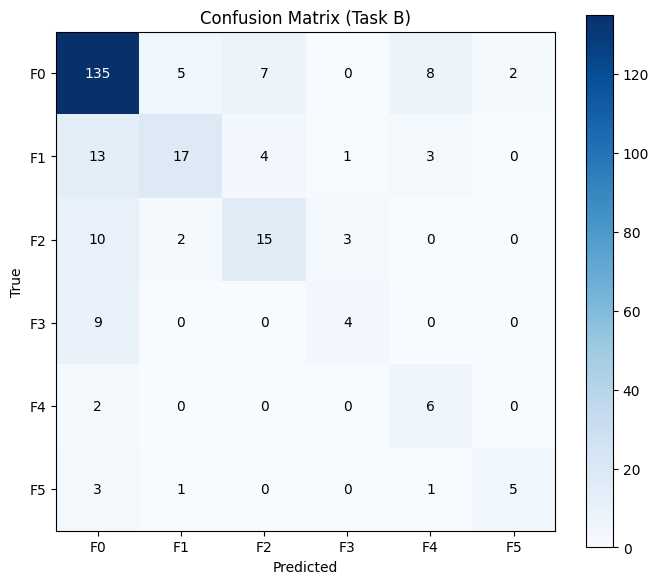

In [60]:
# --- Final Evaluation ---
model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for batch in val_loader:
        inputs, labels = batch
        inputs = {k: v.to(device) for k, v in inputs.items()}
        labels = labels.to(device)

        logits = model(**inputs)
        preds = torch.argmax(logits, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# --- Print Report & Confusion Matrix ---
print("Classification Report:\n", classification_report(all_labels, all_preds))
cm = confusion_matrix(all_labels, all_preds)

# --- Plot Confusion Matrix ---
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap='Blues')

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max()/2 else 'black')

ax.set_title('Confusion Matrix (Task B)')
ax.set_xlabel('Predicted')
ax.set_ylabel('True')
ax.set_xticks(range(6))
ax.set_yticks(range(6))
ax.set_xticklabels([f"F{i}" for i in range(6)])
ax.set_yticklabels([f"F{i}" for i in range(6)])
fig.colorbar(im)
plt.tight_layout()
plt.show()
